In [56]:
import pandas as pd
import numpy as np
df1 = pd.read_csv('winequality-white.csv', sep = ";")
df2 = pd.read_csv('winequality-red.csv', sep = ";")
df1['wine_type'] = 0
df2['wine_type'] = 1
df = pd.concat([df1, df2])
print(df.shape)
display(df.head())
display(df["quality"].describe())

(6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6,0
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6,0
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6,0
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,0
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,0


count    6497.000000
mean        5.818378
std         0.873255
min         3.000000
25%         5.000000
50%         6.000000
75%         6.000000
max         9.000000
Name: quality, dtype: float64

In [57]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['quality'])
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size = 0.2,
    random_state = 48 
)
print(X_train.shape, X_test.shape)


(5197, 12) (1300, 12)



## Получение результатов Base Line

In [58]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

def rmse(y_true, y_predict):
    return root_mean_squared_error(y_true, y_predict)

baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)

predict_base = baseline.predict(X_test)
print("Baseline RMSE:", rmse(y_test, predict_base))
print("Baseline MAE:", mean_absolute_error(y_test, predict_base))

Baseline RMSE: 0.8745078676754127
Baseline MAE: 0.6907187578632642


## Scaler и приведение к единому диапазону

In [59]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Создание моделей и логарифмирование признаков

In [60]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, PolynomialFeatures, StandardScaler
from sklearn.base import BaseEstimator, TransformerMixin

skewed = ['residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide',
          'volatile acidity', 'sulphates', 'citric acid', 'fixed acidity']

def log_skewed(D):
    D = D.copy()
    D[skewed] = np.log1p(D[skewed])
    return D
    
class Winsorizer(BaseEstimator, TransformerMixin):
    #Обрезаем признаки по квантилям
    def __init__(self, q=0.005):
        self.q = q
    def fit(self, X, y=None):
        self.low_ = X.quantile(self.q)
        self.high_ = X.quantile(1 - self.q)
        return self
    def transform(self, X):
        return X.clip(self.low_, self.high_, axis=1)

linreg = make_pipeline(
    Winsorizer(0.005),
    FunctionTransformer(log_skewed),
    StandardScaler(),
    PolynomialFeatures(degree=2),
    StandardScaler(),
    LinearRegression(),
)

linreg_poly = make_pipeline(
    FunctionTransformer(log_skewed),
    StandardScaler(),
    PolynomialFeatures(degree=2),
    StandardScaler(),
    RidgeCV(alphas=np.logspace(-3, 3, 30)),
)

lasso = make_pipeline(
    FunctionTransformer(log_skewed),
    StandardScaler(),
    PolynomialFeatures(degree=2),
    StandardScaler(),
    LassoCV(alphas=np.logspace(-3, 3, 30), max_iter=10000),
) 

"""lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(alpha=0.01, max_iter=10000))
])"""

randomforest = Pipeline(
    [
        ("model", RandomForestRegressor(n_estimators=100, random_state=27),)
    ]
)
gradientboost = Pipeline(
    [
        ("model", GradientBoostingRegressor(n_estimators=100, random_state=27))
    ]
)


## Обучение моделей и получение таблицы с результатами

In [61]:
from sklearn.preprocessing import FunctionTransformer, PolynomialFeatures, StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline

print(f"{'Модель':<35}{'RMSE':<12}{'MAE':<12}")
print("-" * 59)

models_dict = {
    "Lasso": lasso,
    "Ridge": linreg_poly, 
    "Linear Regression": linreg, 
    "Random Forest": randomforest, 
    "Gradient Boost": gradientboost
}
for name, model in models_dict.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    current_rmse = rmse(y_test, pred)
    current_mae = mean_absolute_error(y_test, pred)
    print(f"{name:<35}{current_rmse:<12.4f}{current_mae:<12.4f}")

Модель                             RMSE        MAE         
-----------------------------------------------------------
Lasso                              0.6905      0.5362      
Ridge                              0.6912      0.5367      
Linear Regression                  0.6903      0.5344      
Random Forest                      0.6040      0.4308      
Gradient Boost                     0.6783      0.5361      


## Feature importance для Random Forest и Gradient Boosting

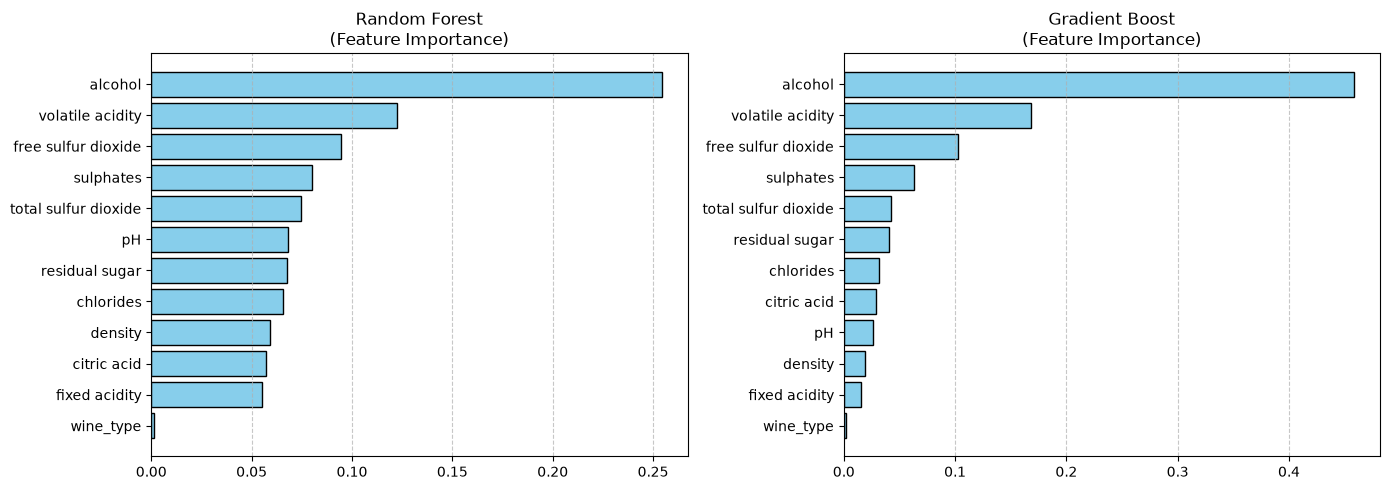

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

trained_models = {
    "Random Forest": randomforest, 
    "Gradient Boost": gradientboost
}

for idx, (name, pipeline) in enumerate(trained_models.items()):

    importances = pipeline.named_steps["model"].feature_importances_
    indices = np.argsort(importances)
    
    axes[idx].barh(range(len(indices)), importances[indices], color='skyblue', edgecolor='black')
    axes[idx].set_yticks(range(len(indices)))
    axes[idx].set_yticklabels(X.columns[indices])
    axes[idx].set_title(f"{name}\n(Feature Importance)")
    axes[idx].grid(axis='x', linestyle='--', alpha=0.7)


plt.tight_layout()
plt.show()

### Коэффициенты линейной регрессии и Ridge на полиномиальных признаках

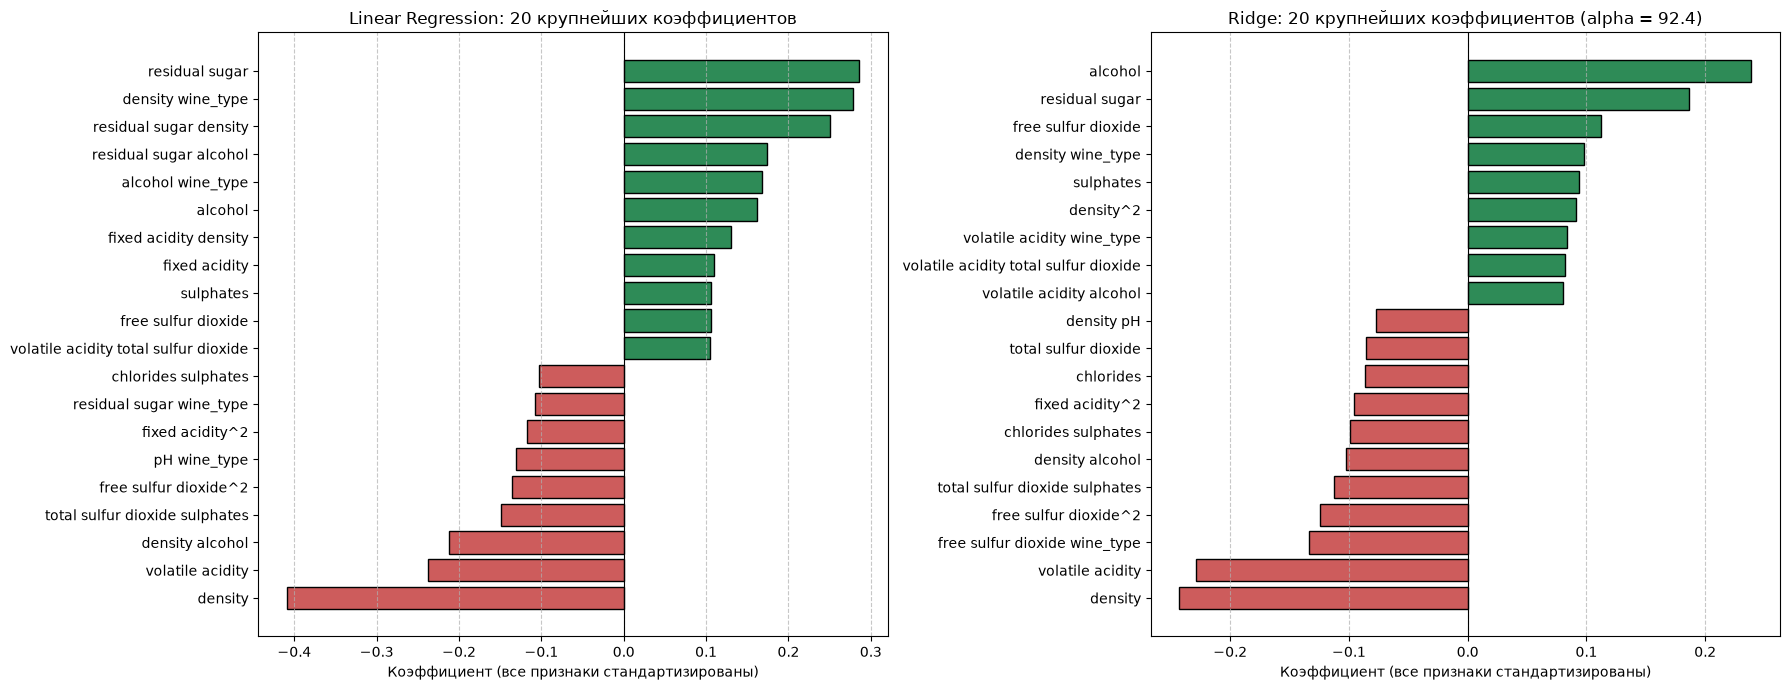

Всего признаков после PolynomialFeatures: 90


In [63]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, (name, pipe) in zip(axes, {"Linear Regression": linreg, "Ridge": linreg_poly}.items()):
    poly = pipe.named_steps["polynomialfeatures"]
    model = pipe.steps[-1][1]

    # имена alcohol volatile acidity это произведение двух признаков, alcohol^2 это квадрат
    coef = pd.Series(model.coef_, index=poly.get_feature_names_out(X.columns)).drop("1")
    top = coef.abs().sort_values(ascending=False).head(20).index
    top_coef = coef[top].sort_values()

    colors = np.where(top_coef > 0, "seagreen", "indianred")
    ax.barh(top_coef.index, top_coef.values, color=colors, edgecolor="black")
    ax.axvline(0, color="black", linewidth=0.8)
    title = f"{name}: 20 крупнейших коэффициентов"
    if hasattr(model, "alpha_"):
        title += f" (alpha = {model.alpha_:.1f})"
    ax.set_title(title)
    ax.set_xlabel("Коэффициент (все признаки стандартизированы)")
    ax.grid(axis="x", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

print("Всего признаков после PolynomialFeatures:", len(coef))

## Анализ ошибок лучшей модели (Random Forest)

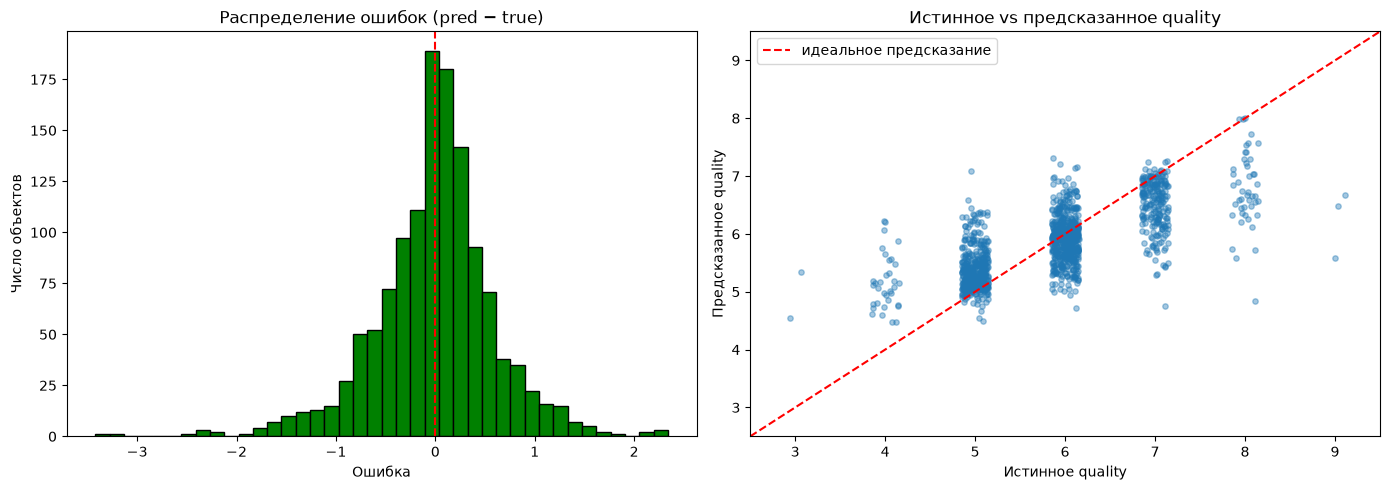

count    1300.000
mean       -0.009
std         0.604
min        -3.420
25%        -0.302
50%         0.020
75%         0.300
max         2.340
Name: error, dtype: float64
Доля объектов с |ошибкой| < 0.5: 0.681
Доля объектов с |ошибкой| > 1:   0.092


In [64]:
rf_pred = randomforest.predict(X_test)

errors = pd.DataFrame({"true": y_test, "pred": rf_pred})
errors["error"] = errors["pred"] - errors["true"]
errors["abs_error"] = errors["error"].abs()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(errors["error"], bins=40, color="green", edgecolor="black")
axes[0].axvline(0, color="red", linestyle="--")
axes[0].set_title("Распределение ошибок (pred − true)")
axes[0].set_xlabel("Ошибка")
axes[0].set_ylabel("Число объектов")

# небольшой случайный сдвиг по x, иначе точки с одинаковым quality сливаются в одну линию
jitter = np.random.default_rng(27).uniform(-0.15, 0.15, len(errors))
lims = [y.min() - 0.5, y.max() + 0.5]
axes[1].scatter(errors["true"] + jitter, errors["pred"], alpha=0.4, s=15)
axes[1].plot(lims, lims, "r--", label="идеальное предсказание")
axes[1].set_xlim(lims)
axes[1].set_ylim(lims)
axes[1].set_title("Истинное vs предсказанное quality")
axes[1].set_xlabel("Истинное quality")
axes[1].set_ylabel("Предсказанное quality")
axes[1].legend()

plt.tight_layout()
plt.show()

print(errors["error"].describe().round(3))
print("Доля объектов с |ошибкой| < 0.5:", round((errors["abs_error"] < 0.5).mean(), 3))
print("Доля объектов с |ошибкой| > 1:  ", round((errors["abs_error"] > 1).mean(), 3))

### Объекты с наибольшими ошибками

In [65]:
worst = errors.sort_values("abs_error", ascending=False).head(10)
display(worst.join(X_test).round(3))

# средние значения признаков для каждого quality в train — чтобы понять, на какой класс "похож" объект
key_features = ["alcohol", "volatile acidity", "free sulfur dioxide", "residual sugar", "density"]
display(X_train.groupby(y_train)[key_features].mean().round(3))

,true,pred,error,abs_error,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,wine_type
774,9,5.58,-3.42,3.42,9.1,0.27,0.45,10.6,0.035,28.0,124.0,0.997,3.20,0.46,10.4,0
3489,8,4.84,-3.16,3.16,6.7,0.28,0.31,7.4,0.041,7.0,81.0,0.993,3.04,0.47,11.4,0
820,9,6.48,-2.52,2.52,6.6,0.36,0.29,1.6,0.021,24.0,85.0,0.990,3.41,0.61,12.4,0
1406,8,5.59,-2.41,2.41,8.2,0.22,0.36,6.8,0.034,12.0,90.0,0.994,3.01,0.38,10.5,0
4745,3,5.34,2.34,2.34,6.1,0.26,0.25,2.9,0.047,289.0,440.0,0.993,3.44,0.64,10.5,0
827,9,6.67,-2.33,2.33,7.4,0.24,0.36,2.0,0.031,27.0,139.0,0.991,3.28,0.48,12.5,0
4339,8,5.72,-2.28,2.28,6.8,0.24,0.29,2.0,0.044,15.0,96.0,0.992,3.23,0.64,10.4,0
440,8,5.74,-2.26,2.26,12.6,0.31,0.72,2.2,0.072,6.0,29.0,0.999,2.88,0.82,9.8,1
812,7,4.76,-2.24,2.24,6.4,0.35,0.28,1.1,0.055,9.0,160.0,0.994,3.42,0.50,9.1,0
812,7,4.76,-2.24,2.24,10.8,0.45,0.33,2.5,0.099,20.0,38.0,0.998,3.24,0.71,10.8,1


,alcohol,volatile acidity,free sulfur dioxide,residual sugar,density
quality,,,,,
3,10.177,0.508,31.482,5.282,0.996
4,10.139,0.452,20.234,4.302,0.995
5,9.832,0.388,30.170,5.811,0.996
6,10.579,0.312,31.252,5.597,0.995
7,11.398,0.293,30.342,4.732,0.993
8,11.667,0.288,35.354,5.445,0.992
9,12.800,0.310,44.000,3.200,0.990


### Качество модели для разных значений quality

,n_train,n_test,mean_pred,mean_error,MAE,RMSE
true,,,,,,
3,28,2,4.945,1.945,1.945,1.985
4,182,34,5.166,1.166,1.166,1.255
5,1696,442,5.365,0.365,0.382,0.510
6,2279,557,5.922,-0.078,0.307,0.401
7,863,216,6.492,-0.508,0.522,0.673
8,147,46,6.787,-1.213,1.213,1.374
9,2,3,6.243,-2.757,2.757,2.797


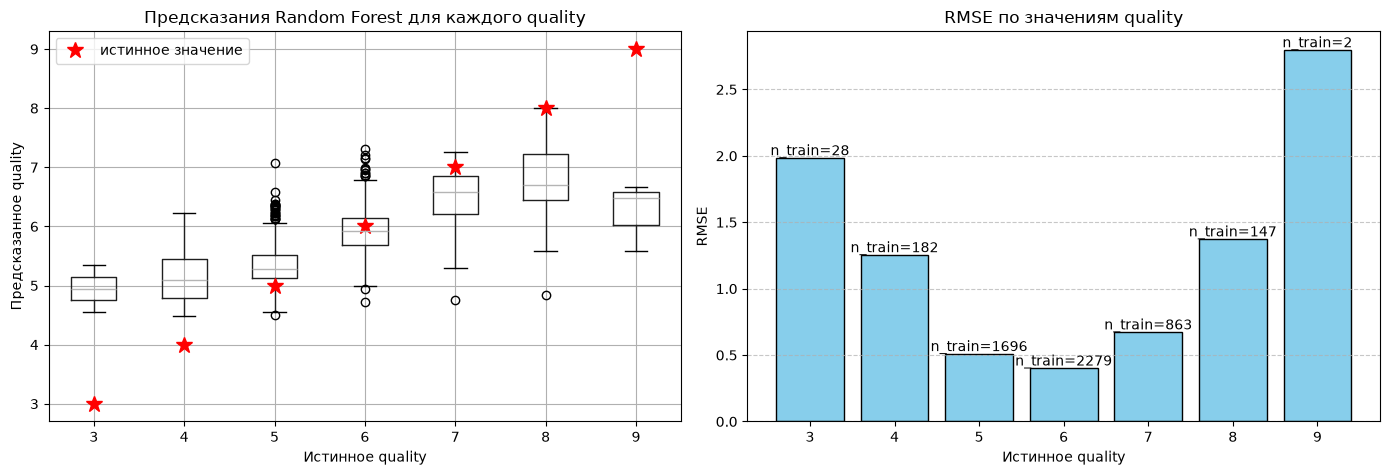

In [66]:
by_quality = errors.groupby("true").agg(
    n_test=("error", "size"),
    mean_pred=("pred", "mean"),
    mean_error=("error", "mean"),
    MAE=("abs_error", "mean"),
    RMSE=("error", lambda e: np.sqrt(np.mean(e ** 2))),
)
by_quality.insert(0, "n_train", y_train.value_counts().reindex(by_quality.index, fill_value=0))
display(by_quality.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

errors.boxplot(column="pred", by="true", ax=axes[0])
axes[0].plot(range(1, len(by_quality) + 1), by_quality.index, "r*", markersize=12, label="истинное значение")
axes[0].set_title("Предсказания Random Forest для каждого quality")
axes[0].set_xlabel("Истинное quality")
axes[0].set_ylabel("Предсказанное quality")
axes[0].legend()
fig.suptitle("")

axes[1].bar(by_quality.index.astype(str), by_quality["RMSE"], color="skyblue", edgecolor="black")
for i, (r, n) in enumerate(zip(by_quality["RMSE"], by_quality["n_train"])):
    axes[1].text(i, r + 0.02, f"n_train={n}", ha="center")
axes[1].set_title("RMSE по значениям quality")
axes[1].set_xlabel("Истинное quality")
axes[1].set_ylabel("RMSE")
axes[1].grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()